# Porter: Delivery Time Estimation using Neural Networks

**Section 2 of 5 (30 marks): Data Preprocessing and Feature Engineering**

| Section | Topic | Marks | File |
|:--:|:--|:--:|:--|
| 1 | Problem Statement, Data Import and Data Structure Analysis | 10 | [open](section_1_problem_and_data.ipynb) |
| 2 | Data Preprocessing and Feature Engineering | 30 | **you are here** |
| 3 | Data Visualization, Outlier Detection and Cleaning | 20 | [open](section_3_visualization_outliers.ipynb) |
| 4 | Model Training with Random Forest | 10 | [open](section_4_random_forest.ipynb) |
| 5 | Regression with Neural Networks | 30 | [open](section_5_neural_network.ipynb) |

**Note.** This notebook continues from [section_1_problem_and_data.ipynb](section_1_problem_and_data.ipynb): it uses the data, variables and functions created in the earlier sections, and the outputs below were saved from one full run of the whole case study. To run the code again, run the cells in order from Section 1 (use `../solution.ipynb` to do this in one go).

<a id="sec2"></a>

# Section 2: Data Preprocessing and Feature Engineering (30 points)

### Objective and Tasks of this Section

**Stage 2 of 5 · 6 Tasks: Data Preprocessing & Feature Engineering**

**Objective:** You will convert the raw timestamp columns into a usable target variable, derive new time-based features, handle missing values, and encode the categorical column so the data is model-ready.

| Task | What to do | Hint |
|:--|:--|:--|
| **Task 2.1** | Convert created_at and actual_delivery_time from object type to proper datetime type. | Think about the pandas function you identified in Stage 1 that parses strings into datetime objects, and confirm the conversion using .info(). |
| **Task 2.2** | Create the target column by finding the time taken for each delivery, then convert it into a single numeric value in minutes. | Think about what subtracting two datetime columns produces, and how you'd turn that duration into a plain number rather than a timedelta object. |
| **Task 2.3** | Extract the hour of day and day of week the order was placed as two new features. | Think about which .dt accessors let you pull a specific component out of a datetime column. |
| **Task 2.4** | Drop the columns that are no longer needed now that the target and time features have been extracted. | Think about which raw columns would now duplicate information already captured in your new features, and could leak into the model if left in. |
| **Task 2.5** | Check for null values across all columns and handle them appropriately. | Think about which pandas method summarizes missing values per column, and what a reasonable default action is when nulls are a small fraction of the data. |
| **Task 2.6** | Encode the categorical column store_primary_category into a numeric form so it can be used by both models. | Think about how you can convert a column to a category dtype and then pull out its underlying integer codes. |

**Evaluation criteria of this section (30 points):**

| Criterion | Done in |
|:--|:--|
| Data cleaning | 2.5 |
| Null value handling | 2.5 |
| Creating the target column(time taken for delivery) from order timestamp and delivery timestamp | 2.2 |
| Getting hour and day of the week | 2.3 |
| Encoding categorical column | 2.6 |

Each task below is marked in its heading, for example `(Task 2.1)`.

---


In Section 1 we understood the data. Now we prepare it for modelling, following the steps of the problem brief: convert the timestamps, create the target (time taken in minutes), get the hour of the day and the day of the week, clean the data, handle null values and encode the categorical columns.

**Flow of this section:**

```
Convert timestamps --> Target in minutes --> Hour & day --> Drop columns --> Clean & nulls --> Encode
```

## 2.1 Convert Timestamps to Datetime (Task 2.1)

`pd.to_datetime` turns text into proper datetime values. First we keep an untouched copy of the data in `df_raw`, so that we can compare before and after later.

In [25]:
df_raw = df.copy()

df["created_at"] = pd.to_datetime(df["created_at"])
df["actual_delivery_time"] = pd.to_datetime(df["actual_delivery_time"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175777 entries, 0 to 175776
Data columns (total 14 columns):
 #   Column                                        Non-Null Count   Dtype         
---  ------                                        --------------   -----         
 0   market_id                                     175777 non-null  float64       
 1   created_at                                    175777 non-null  datetime64[us]
 2   actual_delivery_time                          175777 non-null  datetime64[us]
 3   store_primary_category                        175777 non-null  int64         
 4   order_protocol                                175777 non-null  float64       
 5   total_items                                   175777 non-null  int64         
 6   subtotal                                      175777 non-null  int64         
 7   num_distinct_items                            175777 non-null  int64         
 8   min_item_price                                175777 non-null  in

From the output above, both timestamp columns changed from `str` (text) to `datetime64[us]`, and all 175,777 rows are still non-null. Pandas can now subtract these columns and pull parts out of them.

## 2.2 Create the Target: Time Taken in Minutes (Task 2.2)

Subtracting two datetime columns gives a `Timedelta`. `.dt.total_seconds()` turns it into seconds, and dividing by 60 gives the delivery time in minutes, a plain number a model can learn.

In [26]:
df["time_taken_mins"] = (df["actual_delivery_time"] - df["created_at"]).dt.total_seconds() / 60

df[["created_at", "actual_delivery_time", "time_taken_mins"]].head()

,created_at,actual_delivery_time,time_taken_mins
0,2015-02-06 22:24:17,2015-02-06 23:11:17,47.0
1,2015-02-10 21:49:25,2015-02-10 22:33:25,44.0
2,2015-02-16 00:11:35,2015-02-16 01:06:35,55.0
3,2015-02-12 03:36:46,2015-02-12 04:35:46,59.0
4,2015-01-27 02:12:36,2015-01-27 02:58:36,46.0


In [27]:
df["time_taken_mins"].describe()

count    175777.000000
mean         46.203013
std           9.327424
min          32.000000
25%          39.000000
50%          45.000000
75%          52.000000
max         110.000000
Name: time_taken_mins, dtype: float64

A histogram shows the shape of the new target column.

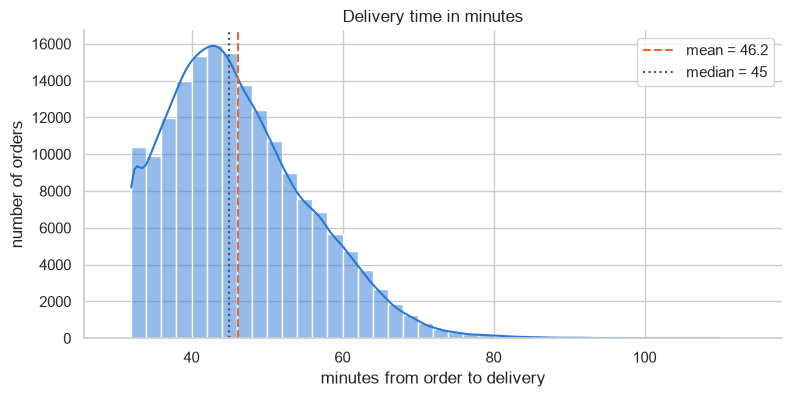

In [28]:
plt.figure(figsize=(9, 4))
sns.histplot(df["time_taken_mins"], bins=range(30, 115, 2), kde=True, color=BLUE)
plt.axvline(df["time_taken_mins"].mean(), color=ORANGE, linestyle="--", linewidth=1.5, label=f"mean = {df['time_taken_mins'].mean():.1f}")
plt.axvline(df["time_taken_mins"].median(), color="#52514e", linestyle=":", linewidth=1.5, label=f"median = {df['time_taken_mins'].median():.0f}")
plt.title("Delivery time in minutes")
plt.xlabel("minutes from order to delivery")
plt.ylabel("number of orders")
plt.legend()
plt.show()

From the output above, delivery time runs from 32 to 110 minutes, with a mean of 46.2 and a median of 45. The mean is above the median and the longest delivery is far above the quartiles (39 and 52), so the distribution is stretched to the right: most deliveries take 39 to 52 minutes and a few take much longer.

## 2.3 Hour of the Day and Day of the Week (Task 2.3)

The `.dt` accessor pulls the hour and the weekday out of the order time. Monday is 0 and Sunday is 6.

In [29]:
df["hour"] = df["created_at"].dt.hour
df["day_of_week"] = df["created_at"].dt.day_of_week

df[["created_at", "hour", "day_of_week"]].head()

,created_at,hour,day_of_week
0,2015-02-06 22:24:17,22,4
1,2015-02-10 21:49:25,21,1
2,2015-02-16 00:11:35,0,0
3,2015-02-12 03:36:46,3,3
4,2015-01-27 02:12:36,2,1


## 2.4 Drop Columns That Are No Longer Needed (Task 2.4)

- `created_at` is now represented by `hour` and `day_of_week`.
- `actual_delivery_time` is the source of the target, so keeping it would give the answer to the model (data leakage).
- `estimated_store_to_consumer_driving_duration` is in the file, but it is not part of the data dictionary of the problem brief. We follow the brief and use only the columns it describes.

In [30]:
df = df.drop(columns=["created_at", "actual_delivery_time", "estimated_store_to_consumer_driving_duration"])

df.columns.tolist()

['market_id',
 'store_primary_category',
 'order_protocol',
 'total_items',
 'subtotal',
 'num_distinct_items',
 'min_item_price',
 'max_item_price',
 'total_onshift_dashers',
 'total_busy_dashers',
 'total_outstanding_orders',
 'time_taken_mins',
 'hour',
 'day_of_week']

## 2.5 Data Cleaning and Null Values (Task 2.5)

### Data Cleaning: Impossible Values

In Section 1 we found values that cannot be real: negative prices, negative partner counts, a zero subtotal, and a cheapest item that costs more than the costliest. First we count how many rows break each rule.

In [31]:
rules = {
    "min_item_price < 0": df["min_item_price"] < 0,
    "total_onshift_dashers < 0": df["total_onshift_dashers"] < 0,
    "total_busy_dashers < 0": df["total_busy_dashers"] < 0,
    "total_outstanding_orders < 0": df["total_outstanding_orders"] < 0,
    "subtotal == 0": df["subtotal"] == 0,
    "min_item_price > max_item_price": df["min_item_price"] > df["max_item_price"],
}

rule_counts = pd.Series({name: int(mask.sum()) for name, mask in rules.items()})
rule_counts

min_item_price < 0                  12
total_onshift_dashers < 0           21
total_busy_dashers < 0              21
total_outstanding_orders < 0        41
subtotal == 0                      161
min_item_price > max_item_price    701
dtype: int64

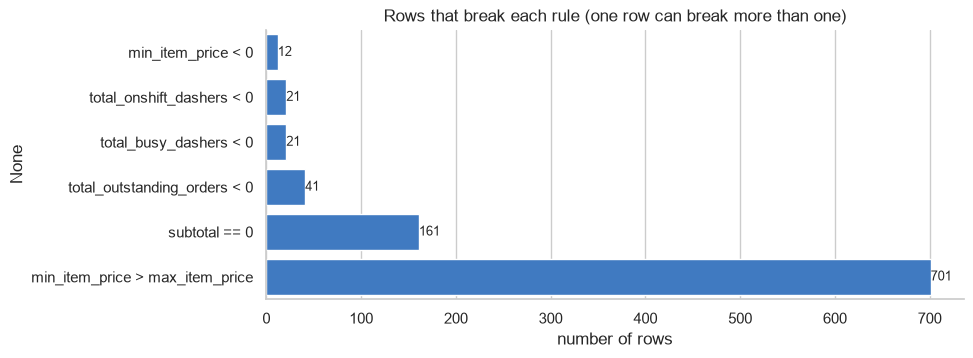

In [32]:
plt.figure(figsize=(9, 3.5))
ax = sns.barplot(x=rule_counts.values, y=rule_counts.index, color=BLUE)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", fontsize=9)
plt.title("Rows that break each rule (one row can break more than one)")
plt.xlabel("number of rows")
plt.show()

These rows are a tiny share of the data, so we remove them. `pd.concat(...).any(axis=1)` marks a row if it breaks at least one rule.

The rows where busy partners exceed on-duty partners are **not** removed. There are far too many of them to be mistakes (Section 1.3).

In [33]:
bad_rows = pd.concat(rules.values(), axis=1).any(axis=1)
print("Rows removed:", bad_rows.sum(), f"({bad_rows.mean() * 100:.2f}% of the data)")

df = df[~bad_rows].reset_index(drop=True)
print("Shape after cleaning:", df.shape)

Rows removed: 940 (0.53% of the data)
Shape after cleaning: (174837, 14)


From the output above, 940 rows (0.53%) broke at least one rule and were removed, which leaves 174,837 rows. The most common problem was a cheapest item that costs more than the costliest (701 rows), followed by a zero subtotal (161 rows).

### Null Values

`df.isnull().sum()` counts the null values in every column. If only a tiny share of rows had nulls we would drop them, and otherwise we would fill them (for example with the median).

In [34]:
print("Total null values:", int(df.isnull().sum().sum()))
df.isnull().sum()

Total null values: 0


market_id                   0
store_primary_category      0
order_protocol              0
total_items                 0
subtotal                    0
num_distinct_items          0
min_item_price              0
max_item_price              0
total_onshift_dashers       0
total_busy_dashers          0
total_outstanding_orders    0
time_taken_mins             0
hour                        0
day_of_week                 0
dtype: int64

From the output above, there are no null values in any column, so nothing had to be dropped or filled. Cleaning the impossible values and creating the target did not create any new nulls.

## 2.6 Encoding the Categorical Column (Task 2.6)

`store_primary_category` has 73 different values. As in the problem brief, we convert the column to the `category` type and take its integer codes. `market_id` and `order_protocol` are stored as decimals (`1.0`, `2.0`), so we convert them to integers.

In [35]:
df["store_category_code"] = df["store_primary_category"].astype("category").cat.codes
df["market_id"] = df["market_id"].astype(int)
df["order_protocol"] = df["order_protocol"].astype(int)

df[["store_primary_category", "store_category_code"]].drop_duplicates().sort_values("store_category_code").head()

,store_primary_category,store_category_code
11940,0,0
32798,1,1
4062,2,2
133349,3,3
0,4,4


In [36]:
df = df.drop(columns=["store_primary_category"])

df.head()

,market_id,order_protocol,total_items,subtotal,num_distinct_items,min_item_price,max_item_price,total_onshift_dashers,total_busy_dashers,total_outstanding_orders,time_taken_mins,hour,day_of_week,store_category_code
0,1,1,4,3441,4,557,1239,33.0,14.0,21.0,47.0,22,4,4
1,2,2,1,1900,1,1400,1400,1.0,2.0,2.0,44.0,21,1,46
2,2,3,4,4771,3,820,1604,8.0,6.0,18.0,55.0,0,0,36
3,1,1,1,1525,1,1525,1525,5.0,6.0,8.0,59.0,3,3,38
4,1,1,2,3620,2,1425,2195,5.0,5.0,7.0,46.0,2,1,38


**Note:** `market_id` and `order_protocol` are also labels, so we turn them into one-hot columns (`pd.get_dummies`) just before modelling in Section 4. That keeps the original columns available for the charts in Section 3.

In [37]:
print("Shape after Section 2:", df.shape)
df.dtypes

Shape after Section 2: (174837, 14)


market_id                     int64
order_protocol                int64
total_items                   int64
subtotal                      int64
num_distinct_items            int64
min_item_price                int64
max_item_price                int64
total_onshift_dashers       float64
total_busy_dashers          float64
total_outstanding_orders    float64
time_taken_mins             float64
hour                          int32
day_of_week                   int32
store_category_code            int8
dtype: object

From the output above, `store_category_code` now holds an integer code for every restaurant category (in this file the code happens to equal the original category number), and `market_id` and `order_protocol` are integers. The table has 174,837 rows and 14 columns, and every column is numeric.

**Note:** These codes are labels, not amounts: category 40 is not "more" than category 4. A Random Forest copes with this because it only compares thresholds, but a neural network reads the code as a number. This is a limitation of the encoding the brief asks for.

## Section 2 Summary: Objective and How It Was Addressed

**Motto of this section:** *Turn raw records into a clean, numeric table the models can learn from.*

| Task | Where it is addressed | Result |
|:--|:--|:--|
| **Task 2.1:** convert both timestamps to datetime | **2.1**: `pd.to_datetime`, checked with `df.info()` | Both columns are `datetime64[us]` |
| **Task 2.2:** target in minutes | **2.2**: subtract the columns, `.dt.total_seconds() / 60` | `time_taken_mins`: 32 to 110 minutes, mean 46.2 |
| **Task 2.3:** hour of day and day of week | **2.3**: `.dt.hour` and `.dt.day_of_week` | `hour` (0 to 23) and `day_of_week` (Monday = 0) |
| **Task 2.4:** drop columns no longer needed | **2.4**: dropped `created_at`, `actual_delivery_time` (the target's source, so it would leak) and `estimated_store_to_consumer_driving_duration` | 14 columns left |
| **Task 2.5:** nulls and cleaning | **2.5**: six rules for impossible values, then `isnull().sum()` | 940 rows (0.53%) removed; no nulls |
| **Task 2.6:** encode the categorical column | **2.6**: `astype("category").cat.codes` | `store_category_code`; 174,837 rows and 14 columns, all numeric |

**Two decisions to remember:**
- Rows where busy partners exceed on-shift partners (39,290 rows in Section 1) were **kept**. There are far too many of them to be typing mistakes.
- `estimated_store_to_consumer_driving_duration` was **not used**, because the brief's data dictionary does not list it. In the raw file it correlates about 0.46 with delivery time (profiled before this notebook was built), so leaving it out probably costs some accuracy. We did not test that here.